## [LAB-07] 추론통계

### 04-1_일원분산분석

### #01 준비작업

#### 1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *
import numpy as np

# 사후검정을 위한 라이브러리
from pingouin import pairwise_tukey, pairwise_gameshowell

# 시각화 라이브러리
from statannotations.Annotator import Annotator

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


#### 2. 데이터 가져오기

In [2]:
origin = load_data("tree_weight")
origin.head()

📚 소나무 품종별 무게를 조사한 데이터 (출처: 방송통신대학교 통계학개론)


,weight,group
0,4.170,A
1,5.580,A
2,5.180,A
3,6.110,A
4,4.500,A


### #02 사후검정(post hoc)

#### 1. 투키의 HSD
- **Tuckey's Honestly Significant Difference** = "진정으로 유의미한 차이"
- `○○` (명목형)에 따른 `□□` (연속형)의 차이라는 의미로 접근한다.
- 데이터가 등분산성을 만족할 경우 수행한다.

In [3]:
result = pairwise_tukey(data=origin, dv='weight', between='group')
result

,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,A,B,5.032,4.661,0.371,0.279,1.331,0.391,0.510
1,A,C,5.032,5.526,-0.494,0.279,-1.772,0.198,-0.914
2,B,C,4.661,5.526,-0.865,0.279,-3.103,0.012,-1.289


> 사후 분석 결과, B와 C 집단의 평균 차이만 통계적으로 유의하였다 (*p* < 0.05).
> 
> 두 집단의 평균은 각각 4.66과 5.53으로 평균 차이는 -0.870이었으며, 효과크기(Hedges' g)는 -1.29로 큰 수준이었다. 즉, **C 집단의 평균이 B 집단보다 유의하게 높았다.**
> 
> 반면 A와 B (*p* ≥ 0.05) 와 A와 C (*p* ≥ 0.05) 의 평균 차이는 통계적으로 유의하지 않았다.

#### **항목별 의미**

| 항목      | 의미             | 상세 설명                                       |
| ------- | -------------- | ------------------------------------------- |
| A       | 비교 집단 1        | 첫 번째 그룹 이름                                  |
| B       | 비교 집단 2        | 두 번째 그룹 이름                                  |
| mean(A) | 그룹 A의 평균       | 종속변수의 A 그룹 평균                               |
| mean(B) | 그룹 B의 평균       | 종속변수의 B 그룹 평균                               |
| diff    | 평균 차이          | mean(A) − mean(B) / 음수면 B가 더 크고, 양수면 A가 더 큼 |
| se      | 표준오차           | 평균 차이 추정의 표준오차                              |
| T       | t 통계량          | Tukey HSD 기반 검정 통계량                         |
| p-tukey | 보정된 p-value    | Tukey 방법으로 조정된 p값. 0.05 미만이면 유의한 차이         |
| hedges  | Hedges' g 효과크기 | 두 집단 평균 차이의 표준화된 효과 크기 (**0.8 이상이면 큰 효과**)  |

#### 2. Games-Howell 검정
- Games-Howell 검정은 다수의 그룹 간의 평균 차이를 비교하는 통계적 방법 중 하나로, **등분산성 가정이 만족되지 않을 때 사용한다.**
    - 이 예제에 적합한 방법은 아니지만 소스코드의 제시를 목적으로 사용한다.

In [4]:
gh_df = pairwise_gameshowell(data=origin, dv='weight', between='group')
gh_df

,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,A,B,5.032,4.661,0.371,0.311,1.191,16.524,0.475,0.510
1,A,C,5.032,5.526,-0.494,0.231,-2.134,16.786,0.113,-0.914
2,B,C,4.661,5.526,-0.865,0.287,-3.010,14.104,0.024,-1.289


### #03 사후검정 결과 가공하기

#### 1. p-value 컬럼명 변경
- 투키의 검정 결과표를 기준으로 진행한다.
    - 두 검정 방법중 어떤 방법을 적용하더라도 코드의 차이는 없다.
- 투키의 검정은 p-value 컬럼을 "p_tukey"로 표기한다.\
이를 Game-Howell 검정과 동일하게 맞춰준다.

In [5]:
result.rename(columns={"p_tukey": "pval"}, inplace=True)
result

,A,B,mean_A,mean_B,diff,se,T,pval,hedges
0,A,B,5.032,4.661,0.371,0.279,1.331,0.391,0.510
1,A,C,5.032,5.526,-0.494,0.279,-1.772,0.198,-0.914
2,B,C,4.661,5.526,-0.865,0.279,-3.103,0.012,-1.289


#### 2. 검정 정보 추가

In [6]:
# 어떤 사후검정을 사용했는지 식별할 수 있도록 맨 앞에 test 컬럼 추가
result.insert(0, "test", "Tukey HSD")
# p값이 유의수준 미만이면 통계적으로 유의(귀무가설 기각)
result["significant"] = result["pval"] < 0.05

result

,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant
0,Tukey HSD,A,B,5.032,4.661,0.371,0.279,1.331,0.391,0.510,False
1,Tukey HSD,A,C,5.032,5.526,-0.494,0.279,-1.772,0.198,-0.914,False
2,Tukey HSD,B,C,4.661,5.526,-0.865,0.279,-3.103,0.012,-1.289,True


#### **사후검정 효과크기 해석 기준 (Cohen, 1988)**

**Hedges' g**는 두 집단의 평균 차이를 표준화한 효과크기로, 차이가 얼마나 큰지 판단하는 지표.

| 효과크기  | 기준값 (절댓값) | 해석           |
| ----- | --------- | ------------ |
| 작은 효과 | 0.2       | 차이가 작음       |
| 중간 효과 | 0.5       | 어느 정도 차이가 있음 |
| 큰 효과  | 0.8 이상    | 차이가 큼        |

- **p-value**: 집단 간 평균 차이의 통계적 유의성을 판단함.
- **Hedges' g**: 집단 간 차이의 크기를 판단함.
- **부호**: 양수와 음수는 차이의 방향을 나타내므로, 효과크기의 크기는 절댓값으로 판단함.

**주의:** 0.2 / 0.5 / 0.8은 절대적인 경계가 아닌 관례적인 참고 기준이며, 실제 효과의 중요성은 연구 맥락에 따라 판단해야 함.

#### 3. 효과 크기 판정

In [7]:
abs_hedges = result["hedges"].abs()
conditions = [
    abs_hedges >= 0.8,
    abs_hedges >= 0.5,
    abs_hedges >= 0.2,
]
labels = ["Large", "Medium", "Small"]
result["effect_size"] = np.select(conditions, labels, default="Negligible")

result

,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,A,B,5.032,4.661,0.371,0.279,1.331,0.391,0.510,False,Medium
1,Tukey HSD,A,C,5.032,5.526,-0.494,0.279,-1.772,0.198,-0.914,False,Large
2,Tukey HSD,B,C,4.661,5.526,-0.865,0.279,-3.103,0.012,-1.289,True,Large


#### 4. 검정 결과 요약

In [8]:
# 전체 길이
print("비교한 조합 쌍: {0}개".format(len(result)))

# result["significant"]가 True인 행을 1로 놓고 합계를 구하면 유의한 쌍의 개수
print("유의한 쌍: {0}개".format(int(result["significant"].sum())))

# 평균 차이가 가장 큰 쌍과 가장 작은 쌍을 출력
big = result.loc[result["diff"].abs().idxmax()]
print("평균 차이가 가장 큰 쌍: ({0}) vs ({1}) "
      "→ 차이 {2:.3f}, 효과크기 {3}, p-value {4:.3f}".format(
          big["A"], big["B"], abs(big["diff"]), big["effect_size"], big["pval"]))

sm = result.loc[result["diff"].abs().idxmin()]
print("평균 차이가 가장 작은 쌍: ({0}) vs ({1}) "
      "→ 차이 {2:.3f}, 효과크기 {3}, p-value {4:.3f}".format(
          sm["A"], sm["B"], abs(sm["diff"]), sm["effect_size"], sm["pval"]))

비교한 조합 쌍: 3개
유의한 쌍: 1개
평균 차이가 가장 큰 쌍: (B) vs (C) → 차이 0.865, 효과크기 Large, p-value 0.012
평균 차이가 가장 작은 쌍: (A) vs (B) → 차이 0.371, 효과크기 Medium, p-value 0.391


### #04 사후검정 결과 시각화

#### 1. 그룹 순서 추출

In [9]:
order = sorted(origin['group'].unique())
order

['A', 'B', 'C']

#### 2. 비교 대상 그룹 쌍 추출
- A열과 B열을 짝지어 (그룹1, 그룹2) 형태로 묶는다.

In [10]:
pairs = list(zip(result['A'], result['B']))
pairs

[('A', 'B'), ('A', 'C'), ('B', 'C')]

#### 3. 각 그룹에 대응하는 p값 추출

In [11]:
pvalues = list(result['pval'])
pvalues

[0.3908715572045601, 0.19799609065842272, 0.012006454925574839]

#### 4. 시각화 구현

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A vs. B: Custom statistical test, P_val:3.909e-01
B vs. C: Custom statistical test, P_val:1.201e-02
A vs. C: Custom statistical test, P_val:1.980e-01


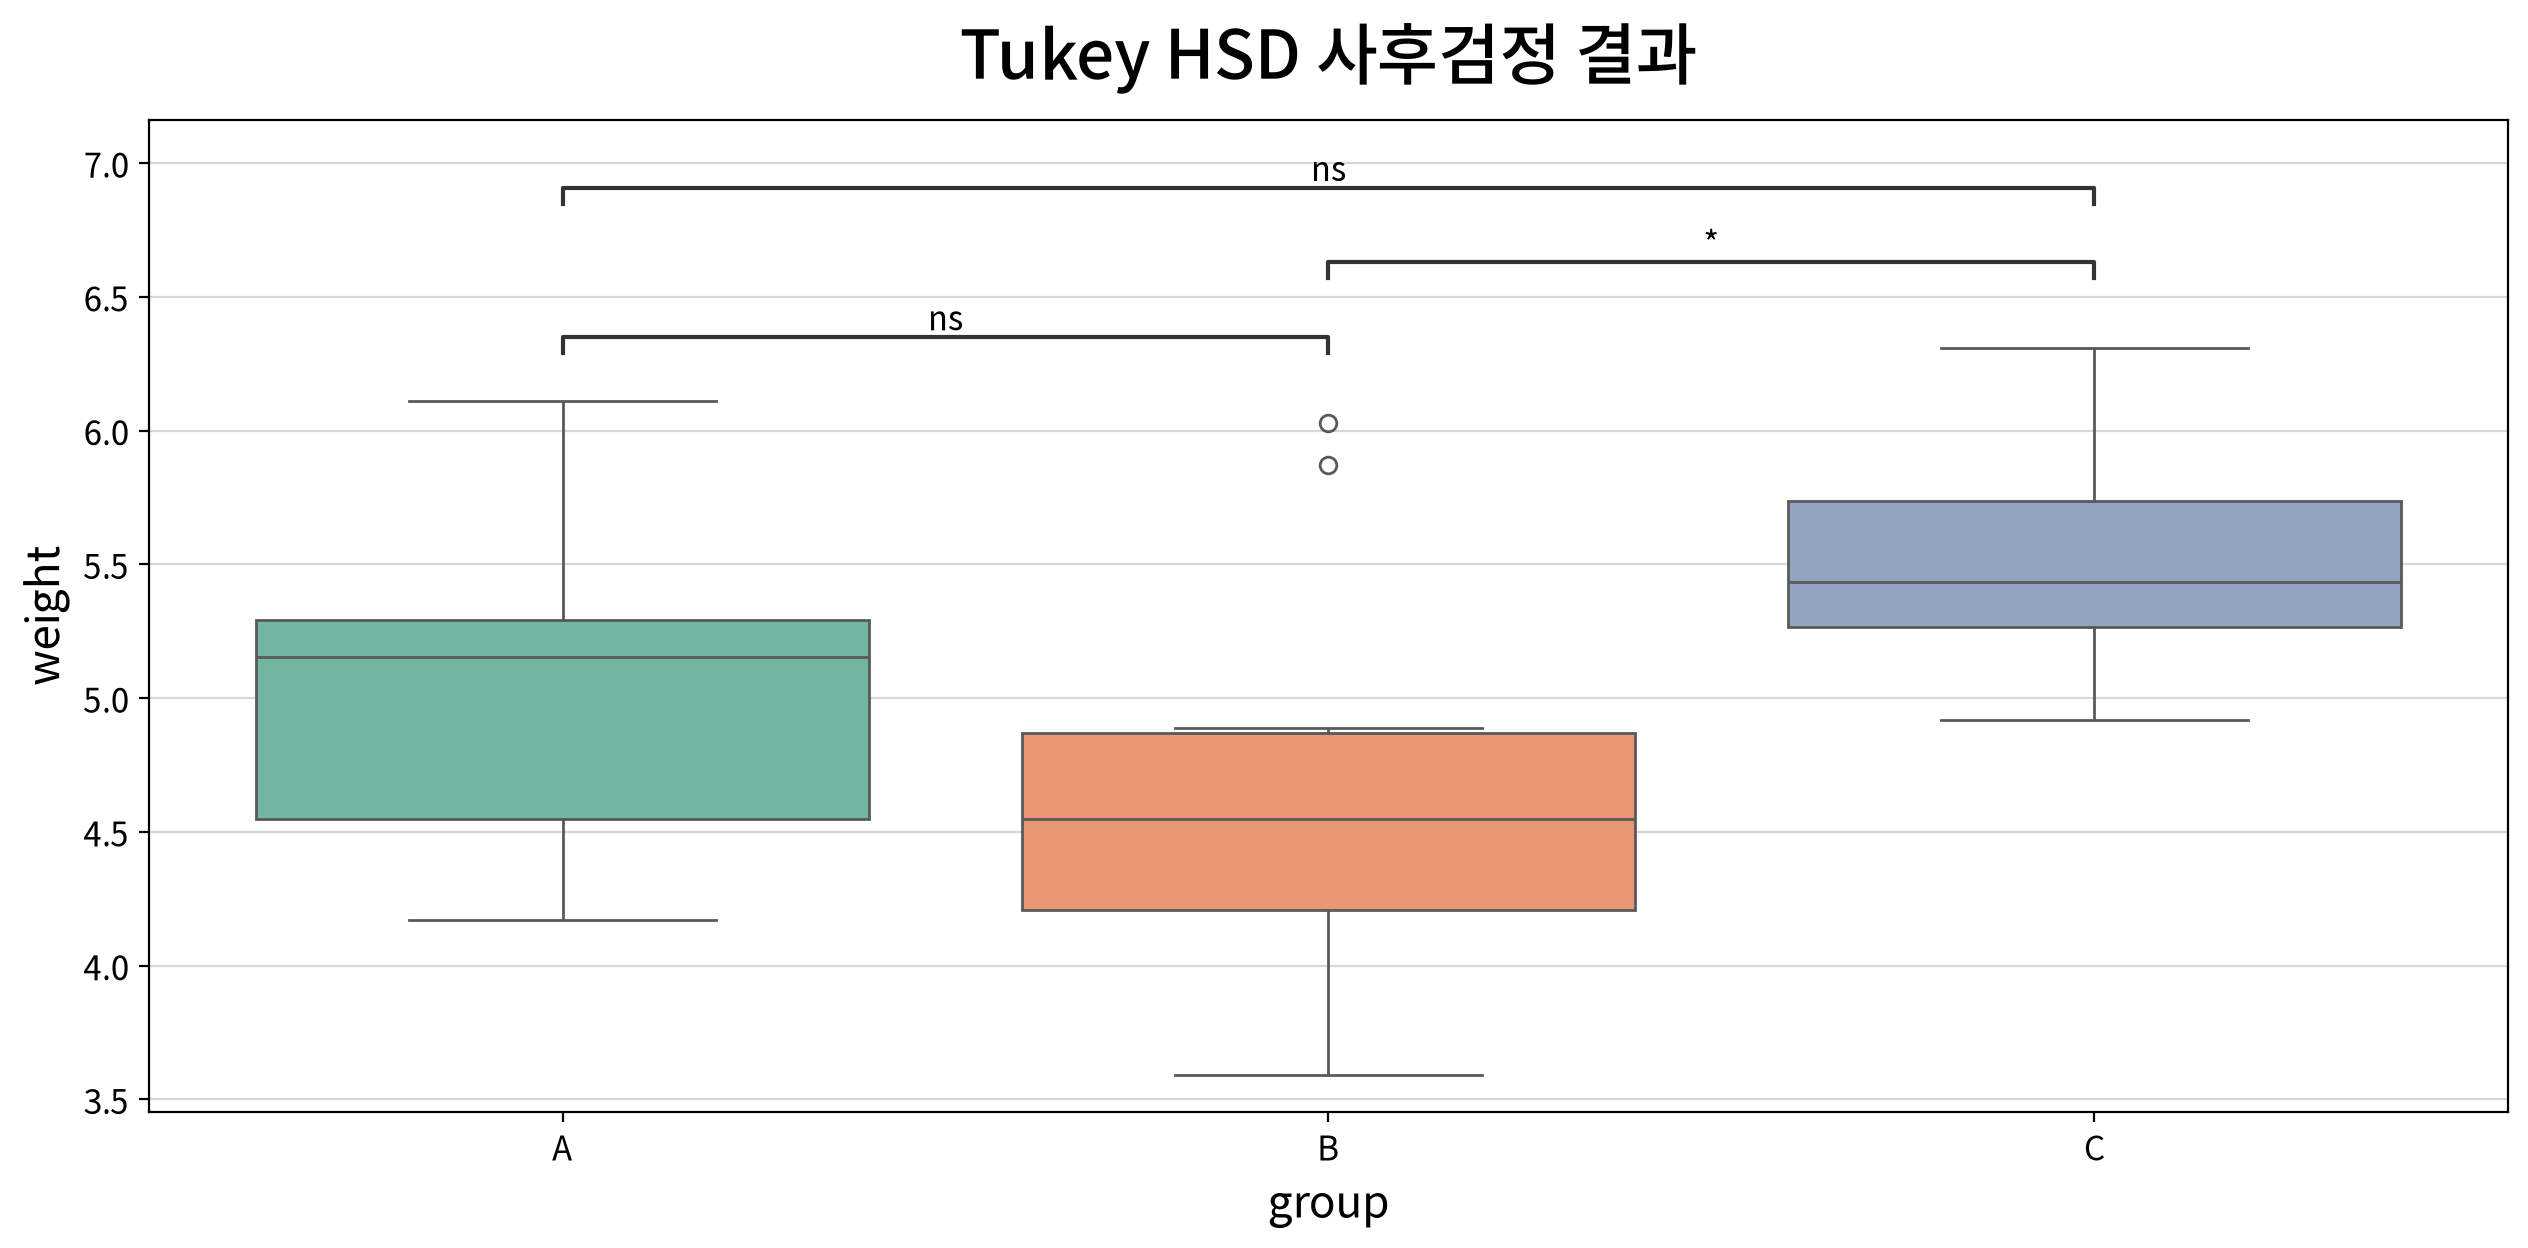

In [12]:
# 그래프 초기화
fig, ax = my_plot.init(title="Tukey HSD 사후검정 결과", xlabel="group",
                       ylabel="weight")

# my_plot.boxplot으로 그룹별 분포 시각화
my_plot.boxplot(data=origin, x='group', y='weight', hue='group', palette='Set2',
                order=order, ax=ax)

# Annotator로 그룹 간 유의성(p-value) 주석을 박스플롯 위에 추가
annotator = Annotator(ax, pairs, data=origin, x='group', y='weight', order=order)

# Tukey 검정에서 구한 p값을 그대로 주입
annotator.set_pvalues(pvalues)
annotator.annotate()

# my_plot.show로 그래프 출력
my_plot.show()

### #05 모듈화 기능 확인

#### 1. 사후검정 및 결과 시각화 일괄 처리

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

A vs. B: Custom statistical test, P_val:3.909e-01
B vs. C: Custom statistical test, P_val:1.201e-02
A vs. C: Custom statistical test, P_val:1.980e-01


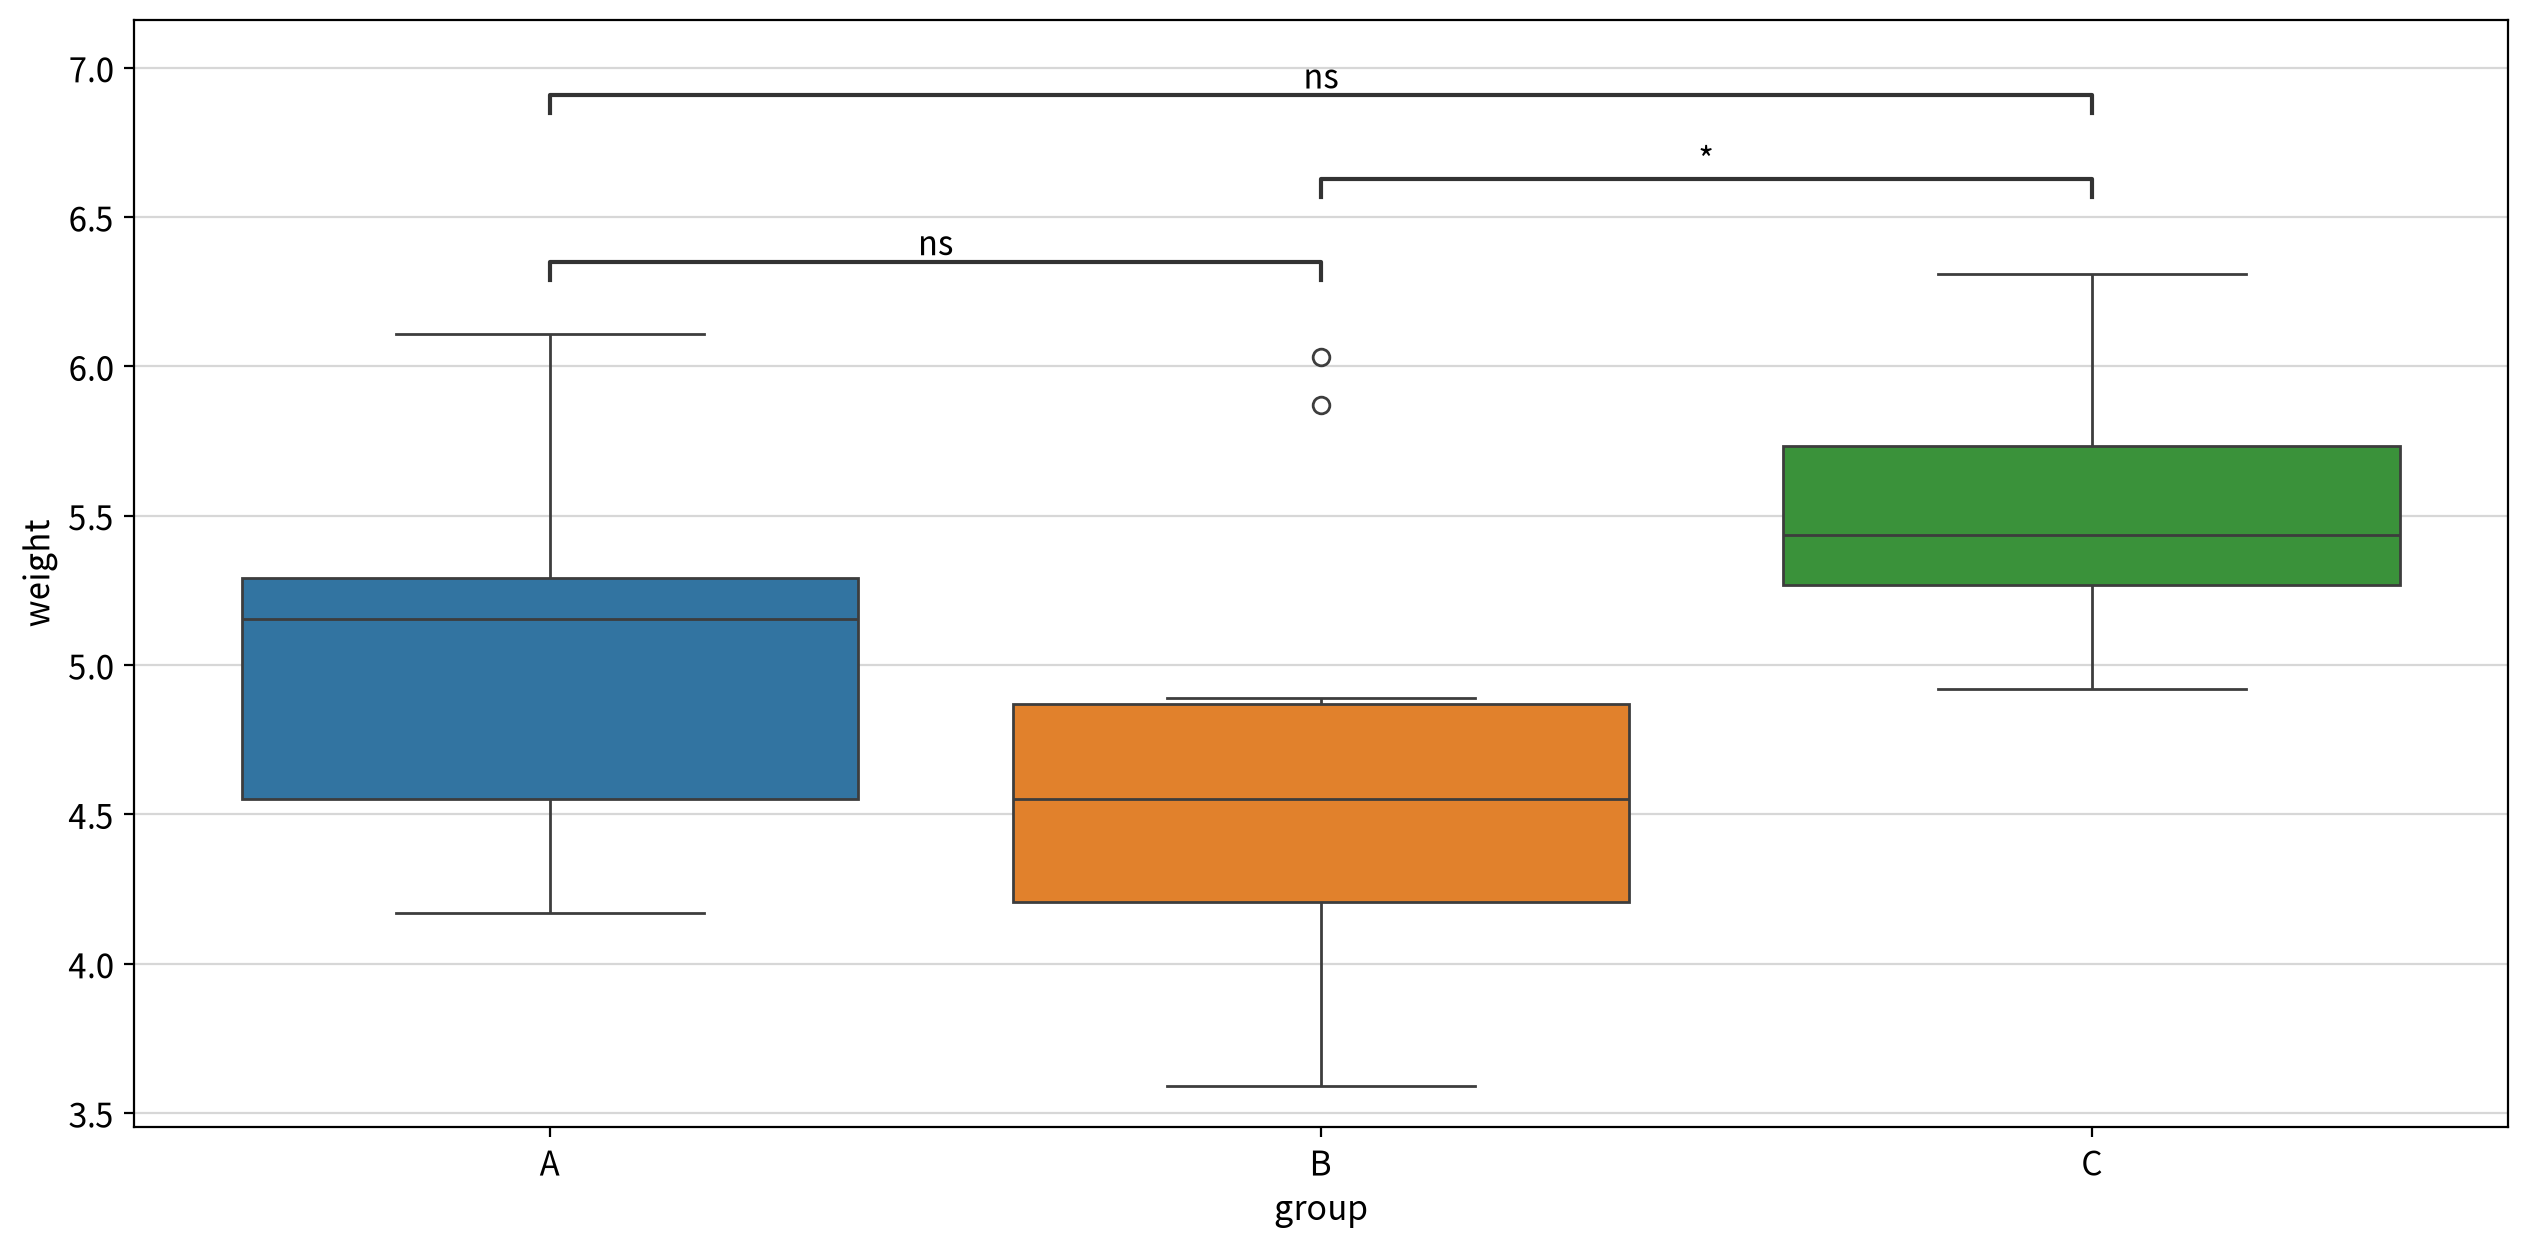

비교한 조합 쌍: 3개
유의한 쌍: 1개
평균 차이가 가장 큰 쌍: (B) vs (C) → 차이 0.865, 효과크기 Large, p-value 0.012
평균 차이가 가장 작은 쌍: (A) vs (B) → 차이 0.371, 효과크기 Medium, p-value 0.391


,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,A,B,5.032,4.661,0.371,0.279,1.331,0.391,0.510,False,Medium
1,Tukey HSD,A,C,5.032,5.526,-0.494,0.279,-1.772,0.198,-0.914,False,Large
2,Tukey HSD,B,C,4.661,5.526,-0.865,0.279,-3.103,0.012,-1.289,True,Large


In [13]:
my_stats.posthoc_oneway(origin, y='weight', between='group')

---

## 연습문제

### 문제 1
- 앞 단원에서 진행한 reading 데이터 셋에 대하여 세 가지 독서 방법에 따라 독서 점수의 평균에 차이가 있다면 구체적으로 어떤 차이가 있는지 검정하라.

In [19]:
df1 = load_data("reading")
df1.head()

📚 유아들을 대상으로 세 가지 읽는 방법을 비교,실험하여 얻은 독서평가 점수 데이터 (출처: 방송통신대학교 통계학개론)


,독서방법,점수
0,B,7.700
1,B,1.500
2,B,4.300
3,B,5.400
4,B,4.300


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

B vs. D: Custom statistical test, P_val:3.400e-01
D vs. G: Custom statistical test, P_val:4.031e-04
B vs. G: Custom statistical test, P_val:8.764e-05


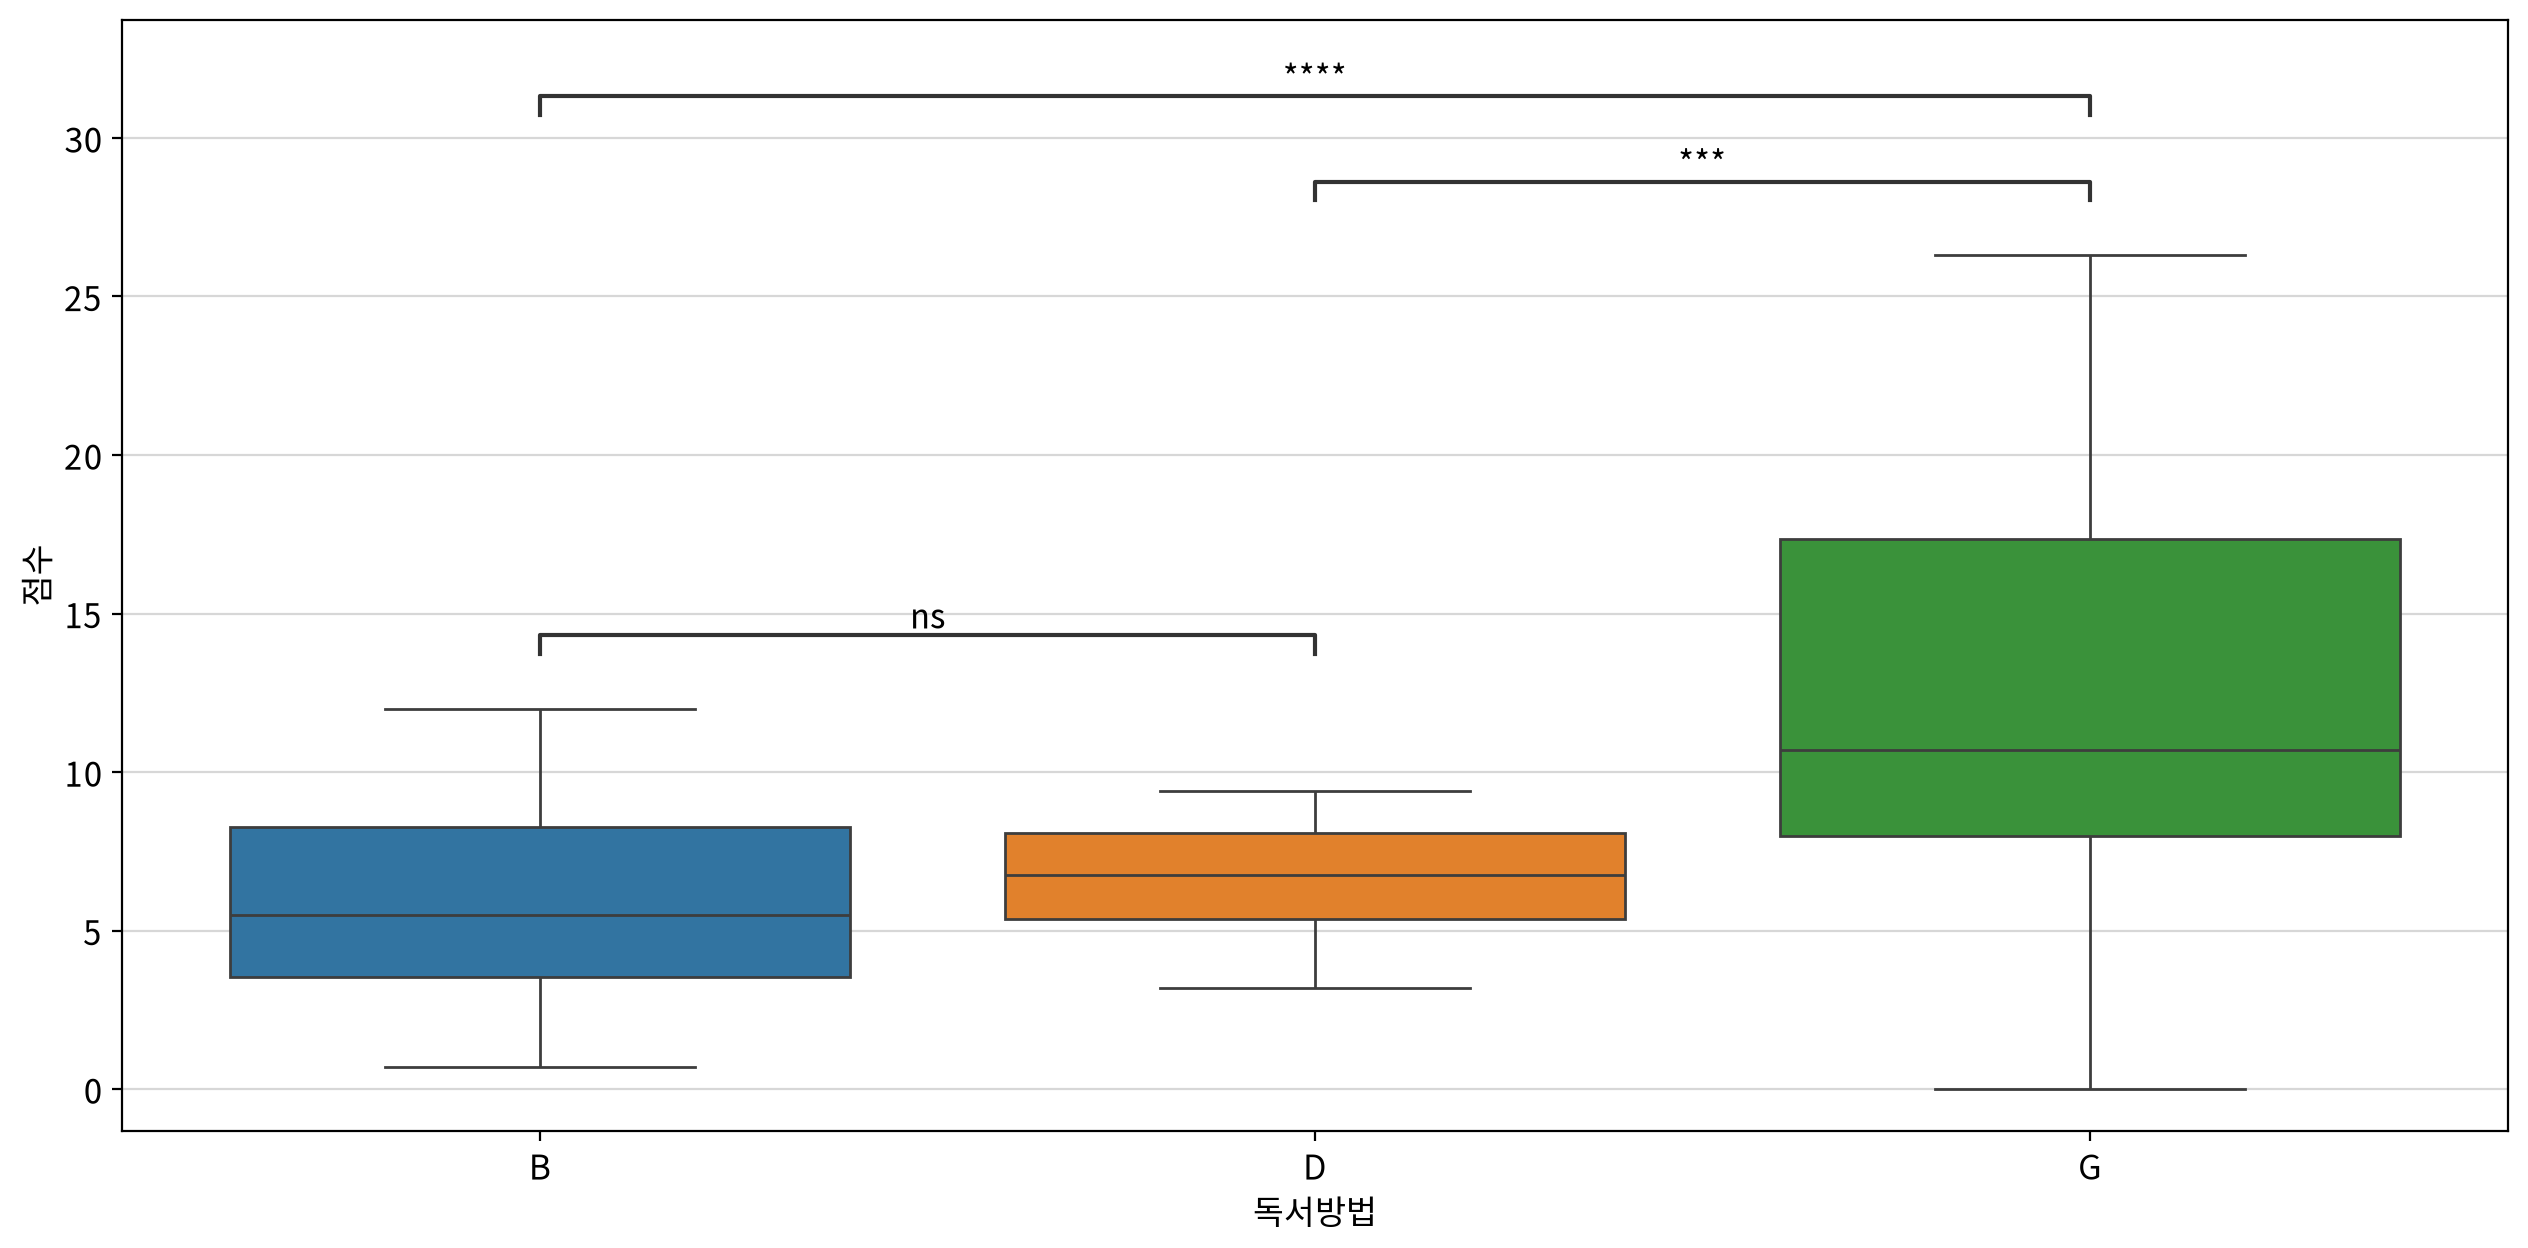

비교한 조합 쌍: 3개
유의한 쌍: 2개
평균 차이가 가장 큰 쌍: (B) vs (G) → 차이 6.799, 효과크기 Large, p-value 0.000
평균 차이가 가장 작은 쌍: (B) vs (D) → 차이 0.961, 효과크기 Small, p-value 0.340


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,B,D,5.732,6.693,-0.961,0.677,-1.421,40.563,0.340,-0.376,False,Small
1,Games-Howell,B,G,5.732,12.531,-6.799,1.457,-4.666,42.964,0.000,-1.137,True,Large
2,Games-Howell,D,G,6.693,12.531,-5.838,1.363,-4.284,34.361,0.000,-1.044,True,Large


In [20]:
my_stats.posthoc_oneway(df1, y='점수', between='독서방법')

> 사후 분석 결과 `B와 G`, `D와 G` 집단의 평균 차이가 통계적으로 유의하였다 (*p* < 0.05).
> 
> B와 G 두 집단의 평균은 각각 5.732과 12.531으로 평균 차이는 -6.799이었으며, 효과크기(Hedges' g)는 -1.137로 큰 수준이었다. 즉, **G 집단의 평균이 B 집단보다 유의하게 높았다.**   
> D와 G 두 집단의 평균은 각각 6.693과 12.531으로 평균 차이는 -5.838이었으며, 효과크기(Hedges' g)는 -1.044로 큰 수준이었다. 즉, **G 집단의 평균이 D 집단보다 유의하게 높았다.**   
> 반면 B와 D(*p* ≥ 0.05) 의 평균 차이는 통계적으로 유의하지 않았다.
> - **결론**: 독서방법 간 차이는 **G 방법이 B·D 방법보다 점수가 유의하게(그리고 큰 효과로) 높기 때문에 발생**한 것이며, B와 D 사이에는 유의한 차이가 없다.

### 문제 2
- 앞 단원에서 진행한 2023년 서울시 상권 매출액 데이터를 사용하여 상권 종류에 따라 평균 매출액에 차이가 있다면 구체적으로 어떤 차이가 있는지 검정하라.

In [21]:
df2 = load_data("commercial")
df2.head()

📚 서울시의 2023년 상권에 따른 분기별 매출액과 매출건수에 대한 자료 (출처: 서울 열린데이터 광장)


,quarter,code,type,name,sales_amount,number_of_sales
0,1,3001491,관광특구,이태원 관광특구,-490799932,2496865
1,1,3001492,관광특구,명동 남대문 북창동 다동 무교동 관광특구,-135495143,10246122
2,1,3001493,관광특구,동대문패션타운 관광특구,92351597,2880324
3,1,3001494,관광특구,종로·청계 관광특구,1609259121,4960006
4,1,3001495,관광특구,잠실 관광특구,-589847108,5995166


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

골목상권 vs. 관광특구: Custom statistical test, P_val:9.915e-01
관광특구 vs. 발달상권: Custom statistical test, P_val:5.900e-01
발달상권 vs. 전통시장: Custom statistical test, P_val:5.105e-04
골목상권 vs. 발달상권: Custom statistical test, P_val:4.280e-08
관광특구 vs. 전통시장: Custom statistical test, P_val:9.623e-01
골목상권 vs. 전통시장: Custom statistical test, P_val:5.415e-01


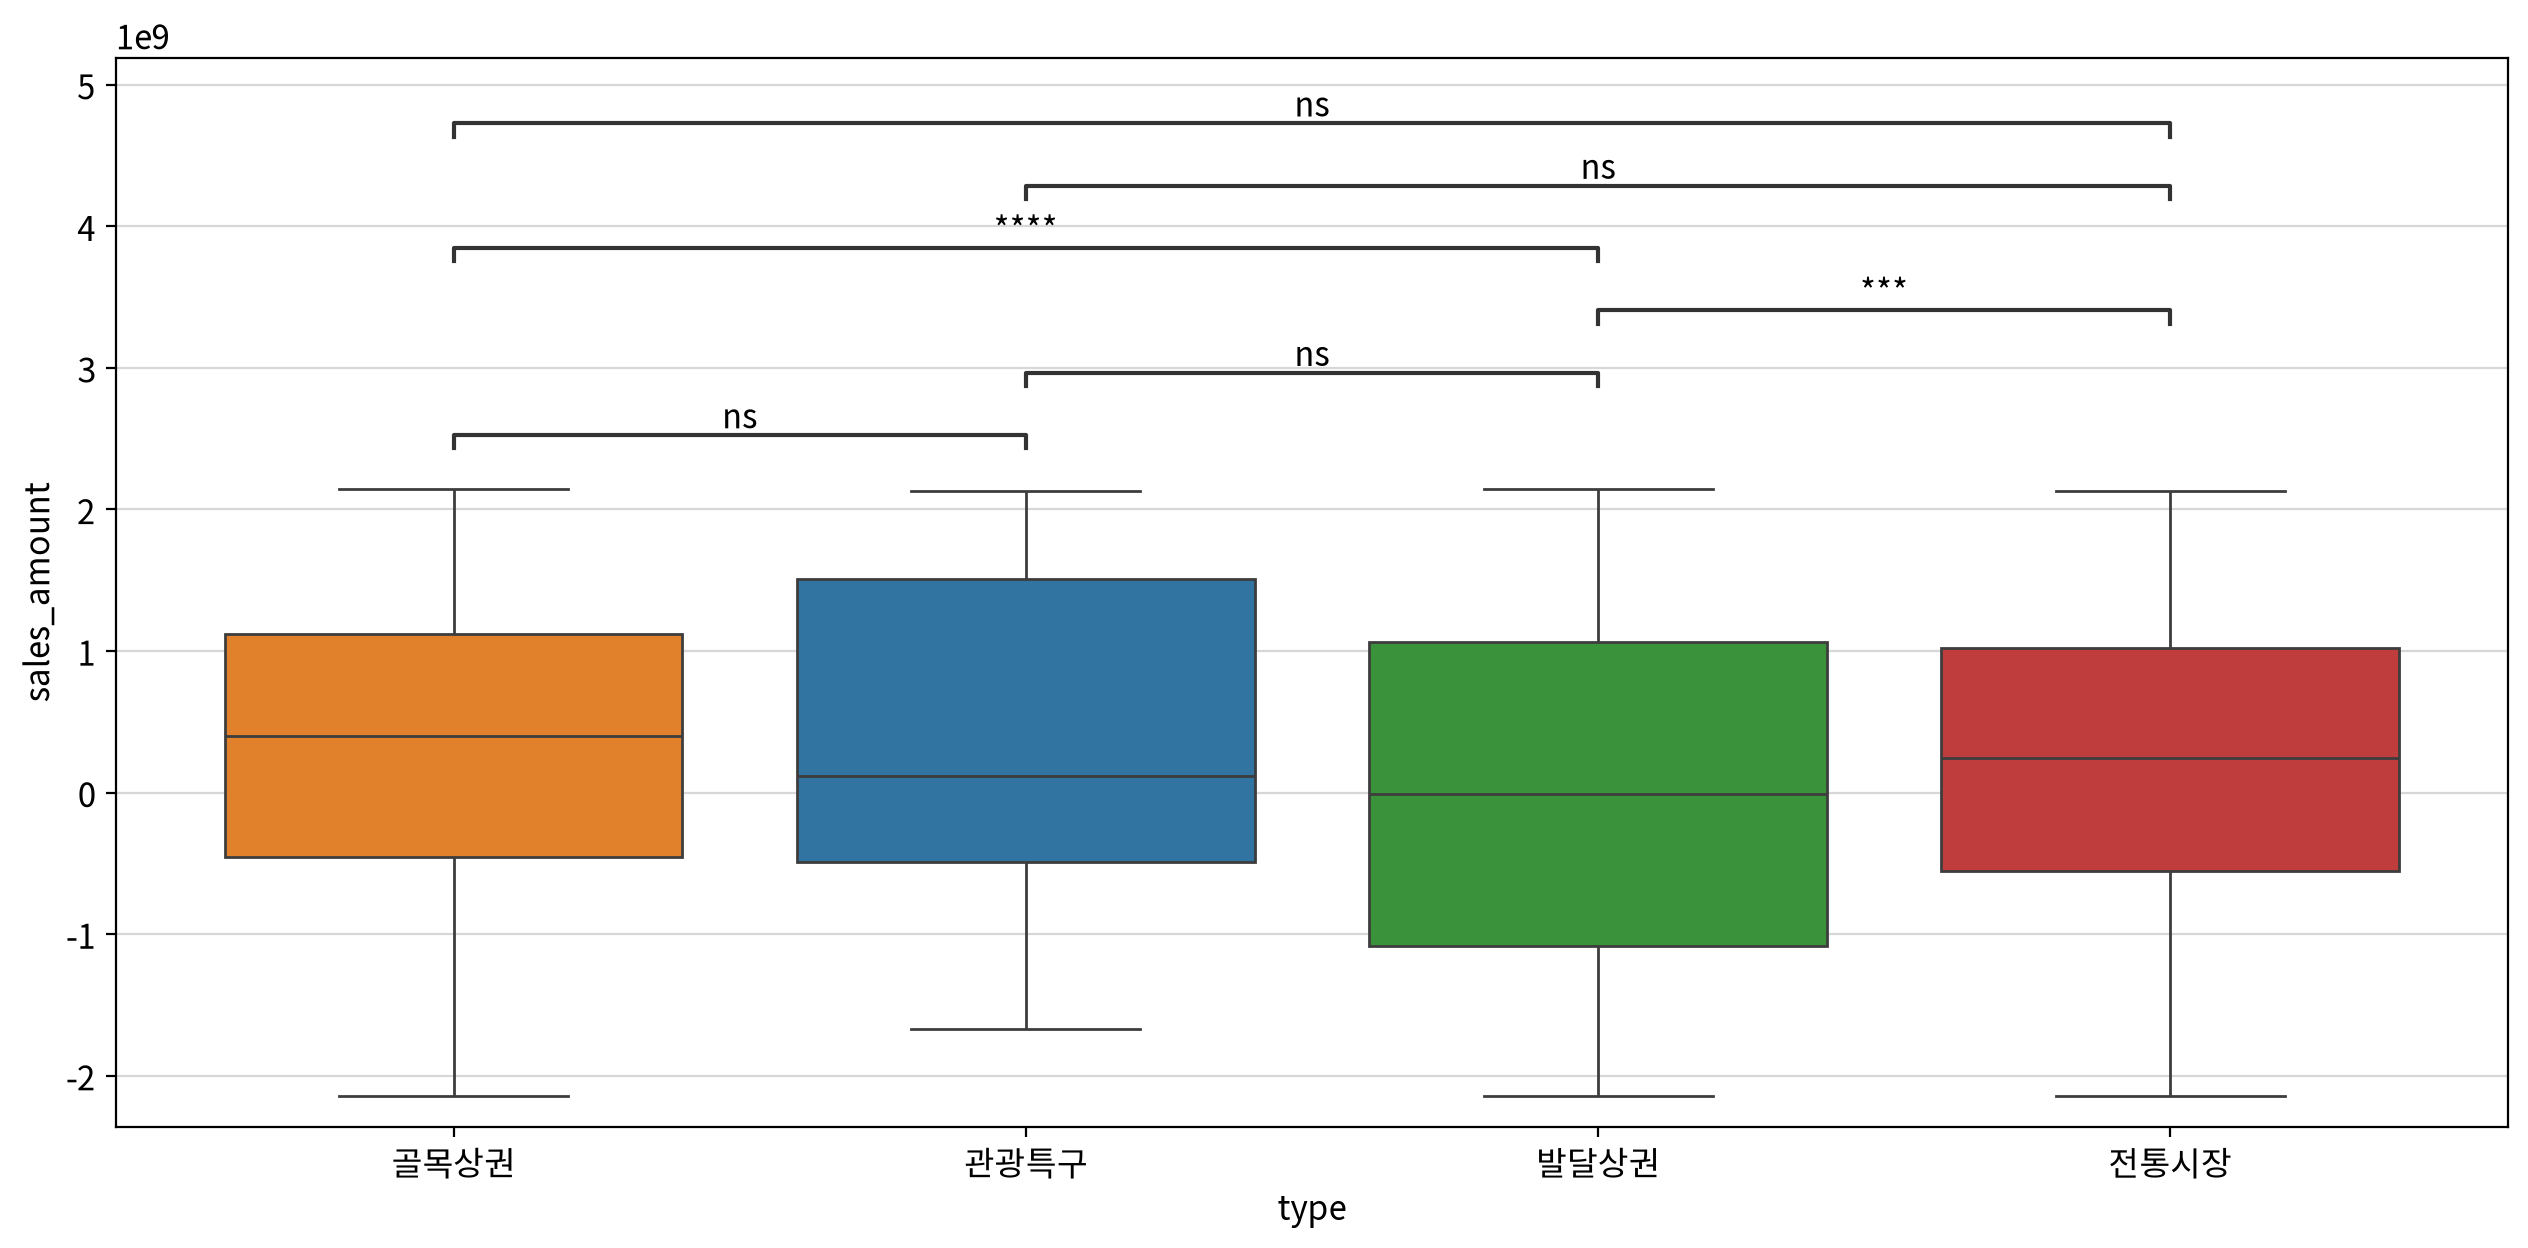

비교한 조합 쌍: 6개
유의한 쌍: 2개
평균 차이가 가장 큰 쌍: (관광특구) vs (발달상권) → 차이 322802912.887, 효과크기 Small, p-value 0.590
평균 차이가 가장 작은 쌍: (골목상권) vs (전통시장) → 차이 49693829.484, 효과크기 Negligible, p-value 0.542


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,골목상권,관광특구,258582970.244,330967382.958,-72384412.715,251741812.201,-0.288,23.230,0.991,-0.064,False,Negligible
1,Games-Howell,골목상권,발달상권,258582970.244,8164470.071,250418500.173,43007801.803,5.823,1429.463,0.000,0.217,True,Small
2,Games-Howell,골목상권,전통시장,258582970.244,208889140.760,49693829.484,37261866.692,1.334,1809.274,0.542,0.044,False,Negligible
3,Games-Howell,관광특구,발달상권,330967382.958,8164470.071,322802912.887,254155558.276,1.270,24.133,0.590,0.261,False,Small
4,Games-Howell,관광특구,전통시장,330967382.958,208889140.760,122078242.198,253246566.603,0.482,23.790,0.962,0.111,False,Negligible
5,Games-Howell,발달상권,전통시장,8164470.071,208889140.760,-200724670.689,51083798.817,-3.929,1996.632,0.001,-0.173,True,Negligible


In [22]:
my_stats.posthoc_oneway(df2, y='sales_amount', between='type')

> 사후 분석 결과 `골목상권와 발달상권`, `발달상권과 전통시장` 집단의 평균 차이가 통계적으로 유의하였다 (*p* < 0.05).
> 
> 골목상권와 발달상권 두 집단의 평균은 각각 258582970.244과 8164470.071으로 평균 차이는 250418500.173이었으며, 효과크기(Hedges' g)는 0.217로 큰 수준이었다.   
> 즉, **골목상권 집단의 평균이 발달상권 집단보다 유의하게 높았다.**   
> 발달상권과 전통시장 두 집단의 평균은 각각 8164470.071과 208889140.760으로 평균 차이는 -200724670.689이었으며, 효과크기(Hedges' g)는 -0.173로 미미한 수준이었다.   
> 즉, **발달상권 집단의 평균이 전통시장 집단보다 유의하게 낮았다.**   
> 반면 다른 그룹쌍(*p* ≥ 0.05) 의 평균 차이는 통계적으로 유의하지 않았다.
> - **결론**: 상권 종류별 매출액은 **모든 조합에서 서로 통계적으로 유의하게 다르며**, 특히 **관광특구의 매출액이 압도적으로 높고 골목상권이 가장 낮다.** 차이를 만드는 핵심 축은 관광특구의 높은 매출이다.

### 문제 3
- tips 데이터 셋은 식당 고객의 결제 금액, 팁, 성별, 흡연 여부, 요일, 시간대, 일행 규모 등 기본 정보를 담은 데이터이다.
- 이 데이터를 활용하여 요일별로 주문금액(total_bills)에 차이가 있는지 검정 확인하고 차이가 있다면 구체적으로 어떤 차이가 있는지 검정하라.

In [25]:
df3 = load_data("tips")
df3.head()

📚 식당 고객의 결제 금액, 팁, 성별, 흡연 여부, 요일, 시간대, 일행 규모 등 기본 정보를 담은 데이터 분석·시각화 실습용 샘플 데이터 (출처: https://www.kaggle.com/datasets/sakshisatre/tips-dataset)

field       description
----------  -------------
total_bill  총 결제 금액
tip         팁 금액
sex         성별
smoker      흡연 여부
day         방문 요일
time        방문 시간대
size        일행 규모



,total_bill,tip,sex,smoker,day,time,size
0,16.990,1.010,Female,No,Sun,Dinner,2
1,10.340,1.660,Male,No,Sun,Dinner,3
2,21.010,3.500,Male,No,Sun,Dinner,3
3,23.680,3.310,Male,No,Sun,Dinner,2
4,24.590,3.610,Female,No,Sun,Dinner,4


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Fri vs. Sat: Custom statistical test, P_val:4.541e-01
Sat vs. Sun: Custom statistical test, P_val:8.968e-01
Sun vs. Thur: Custom statistical test, P_val:6.678e-02
Fri vs. Sun: Custom statistical test, P_val:2.371e-01
Sat vs. Thur: Custom statistical test, P_val:2.374e-01
Fri vs. Thur: Custom statistical test, P_val:9.957e-01


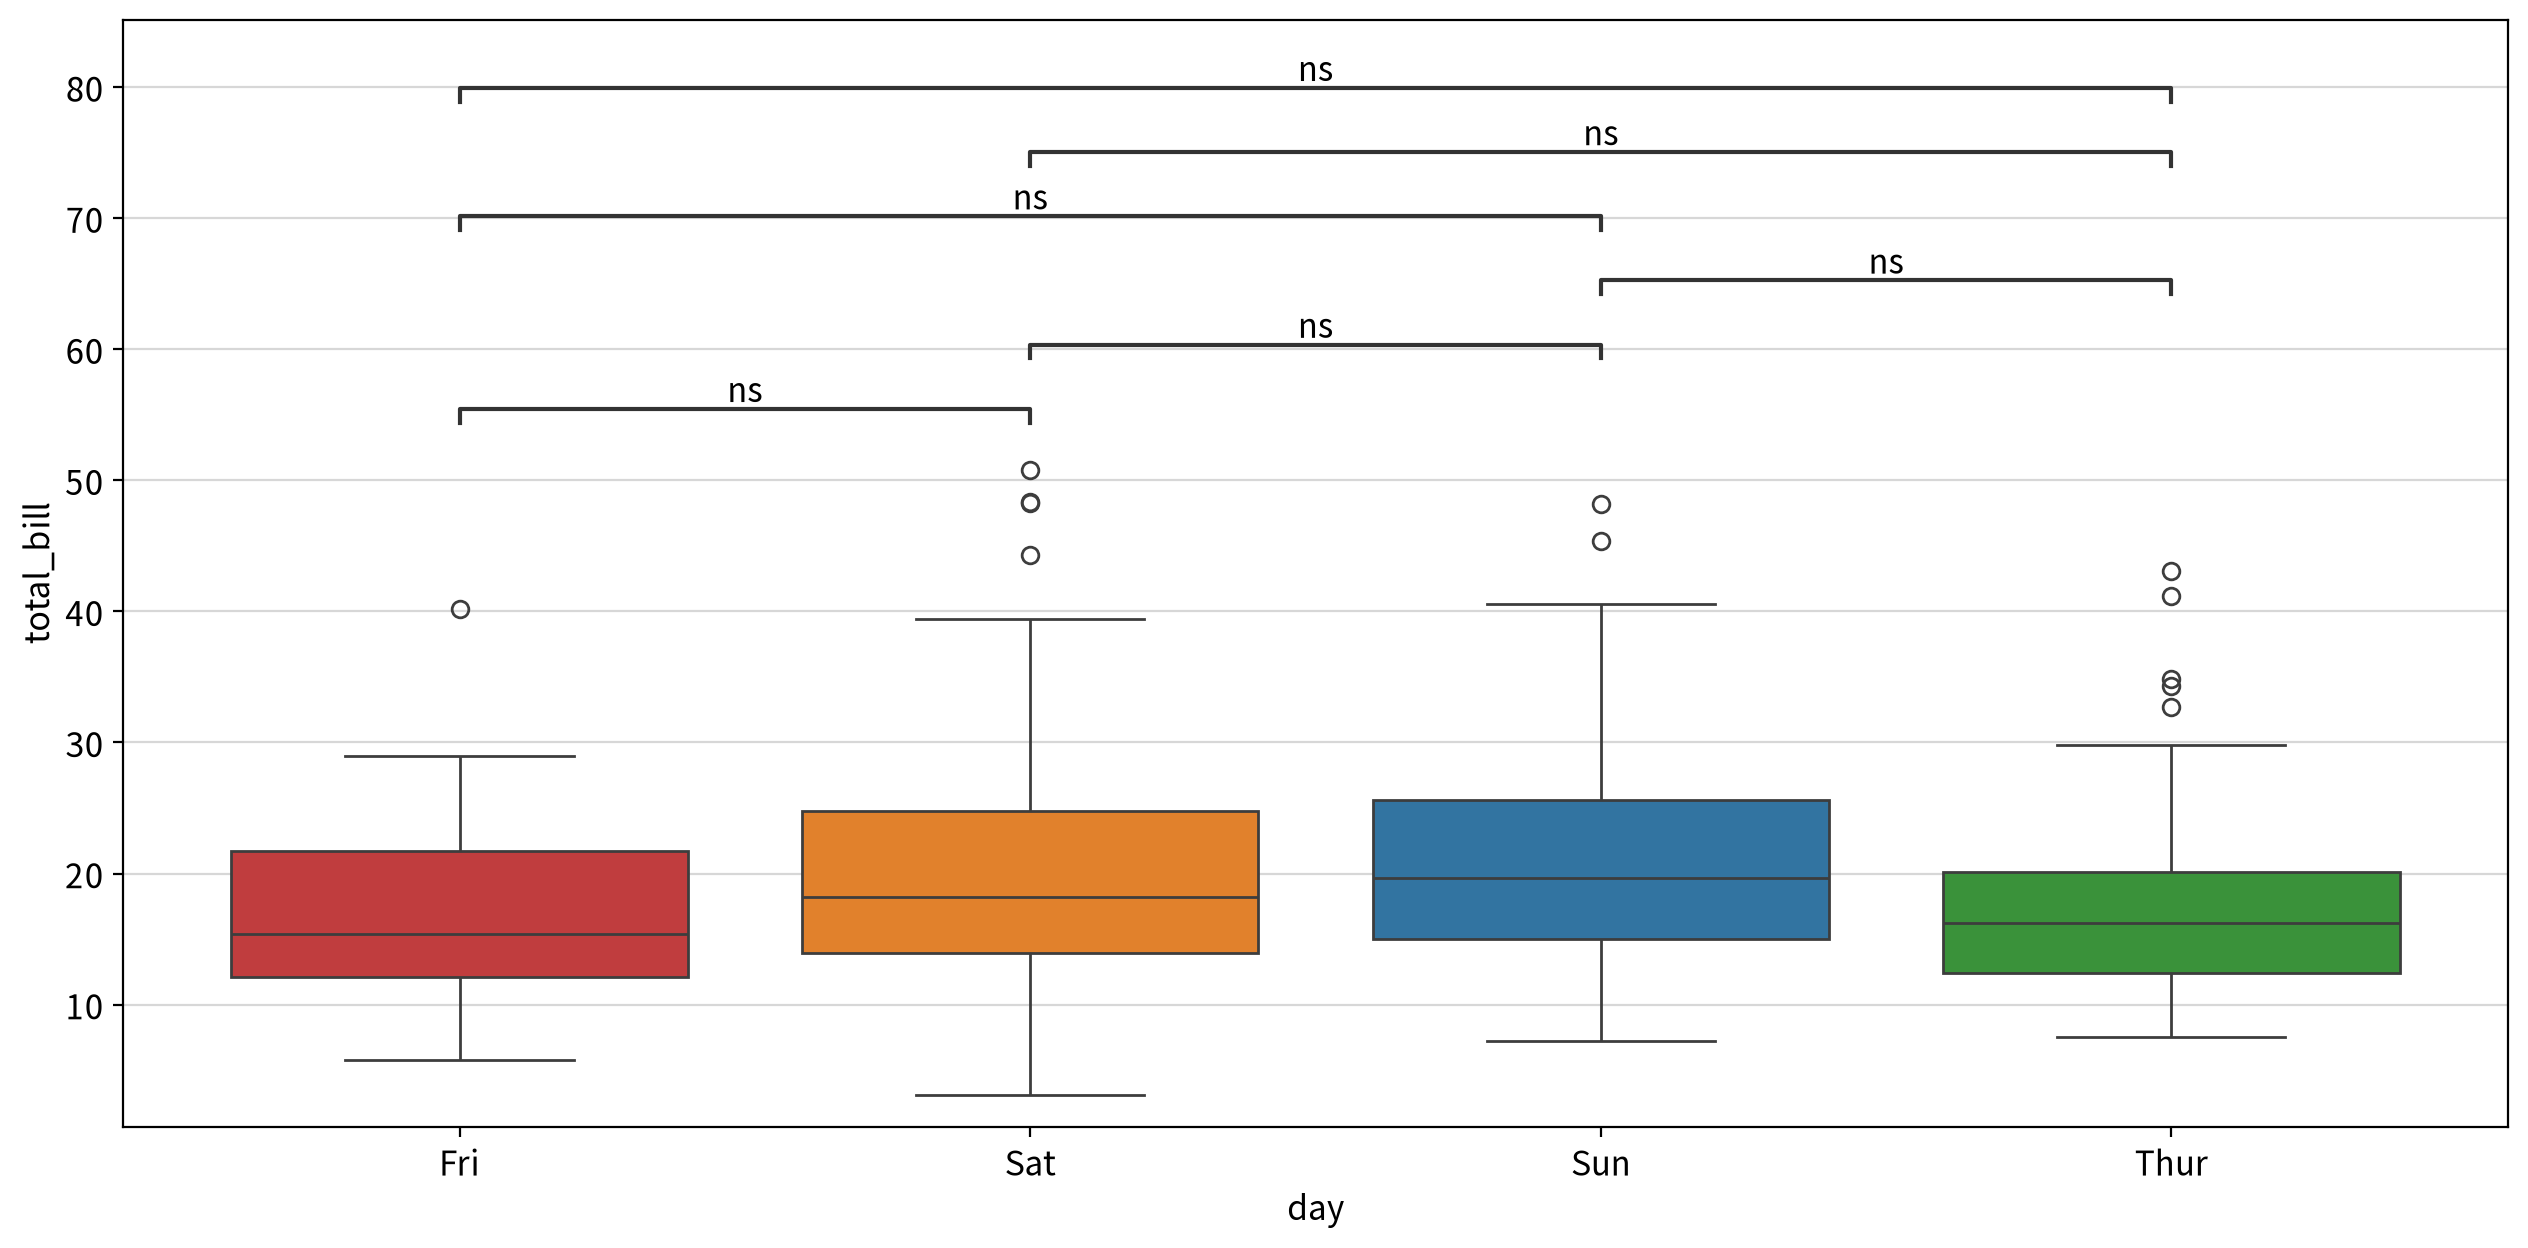

비교한 조합 쌍: 6개
유의한 쌍: 0개
평균 차이가 가장 큰 쌍: (Fri) vs (Sun) → 차이 4.258, 효과크기 Small, p-value 0.237
평균 차이가 가장 작은 쌍: (Fri) vs (Thur) → 차이 0.531, 효과크기 Negligible, p-value 0.996


,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,Fri,Sat,17.152,20.441,-3.290,2.230,-1.475,0.454,-0.352,False,Small
1,Tukey HSD,Fri,Sun,17.152,21.410,-4.258,2.259,-1.885,0.237,-0.484,False,Small
2,Tukey HSD,Fri,Thur,17.152,17.683,-0.531,2.309,-0.230,0.996,-0.066,False,Negligible
3,Tukey HSD,Sat,Sun,20.441,21.410,-0.969,1.383,-0.700,0.897,-0.105,False,Negligible
4,Tukey HSD,Sat,Thur,20.441,17.683,2.759,1.464,1.885,0.237,0.310,False,Small
5,Tukey HSD,Sun,Thur,21.410,17.683,3.727,1.507,2.473,0.067,0.440,False,Small


In [28]:
my_stats.posthoc_oneway(df3, y='total_bill', between='day')

> - **가정 확인**: 사후검정 결과표의 `test`가 **`Tukey HSD`**로 출력되었으므로 요일별 주문금액의 **등분산성 가정이 충족**되어, 일반 분산분석(`anova`)과 Tukey HSD 사후검정이 사용되었다.
> - **분산분석 결과**: F(3, 240) = 2.767, p = 0.042 로 유의수준 0.05보다 작아 **전체적으로는 요일 간 차이가 유의**하다고 판단된다. 다만 효과크기 np2 = 0.033(**Small**)로 그 차이의 크기는 매우 작다.
> - **구체적 차이**: **모든 요일 쌍의 p값이 0.05보다 커서 어떤 쌍도 통계적으로 유의하지 않다.** 가장 근접한 쌍도 Sun vs Thur(p = 0.067)로 유의수준을 넘지 못했고, 효과크기 역시 전부 Small~Negligible 수준이다.
> - **결론**: 분산분석은 "차이가 있다"(p = 0.042)고 했지만, 더 보수적인 **사후검정에서는 구체적으로 차이가 나는 요일 쌍을 찾지 못했다.** 이는 경계적인 p값(0.042)과 작은 효과크기(np2 = 0.033) 때문으로, **요일에 따른 주문금액 차이는 실질적으로 미미하다**고 해석하는 것이 타당하다. (전체 검정과 사후검정 결론이 엇갈릴 수 있는 전형적 사례)

### 문제 4
- tomato 데이터 셋은 효소 성분의 비료가 효소 함량이 증가함에 따라 토마토 모종 포기의 성장에 어떤 영향을 주는지에 대한 실험 결과이다.
- 분산분석을 하여 효소 함량에 따라 토마토 모종 성장에 차이가 나는지 검정하라.

In [31]:
df4 = load_data("tomato")
df4.head()

📚 효소 성분의 비료가 효소 함량이 증가함에 따라 토마토 모종 포기의 성장에 어떤 영향을 주는지에 대한 실험 결과 (출처: 방송통신대학교 통계학 개론)


,효소함량,모종성장
0,0,9.500
1,0,10.000
2,0,10.700
3,0,9.000
4,0,12.400


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 100: Custom statistical test, P_val:7.229e-10
100 vs. 1000: Custom statistical test, P_val:9.517e-07
0 vs. 1000: Custom statistical test, P_val:2.220e-15


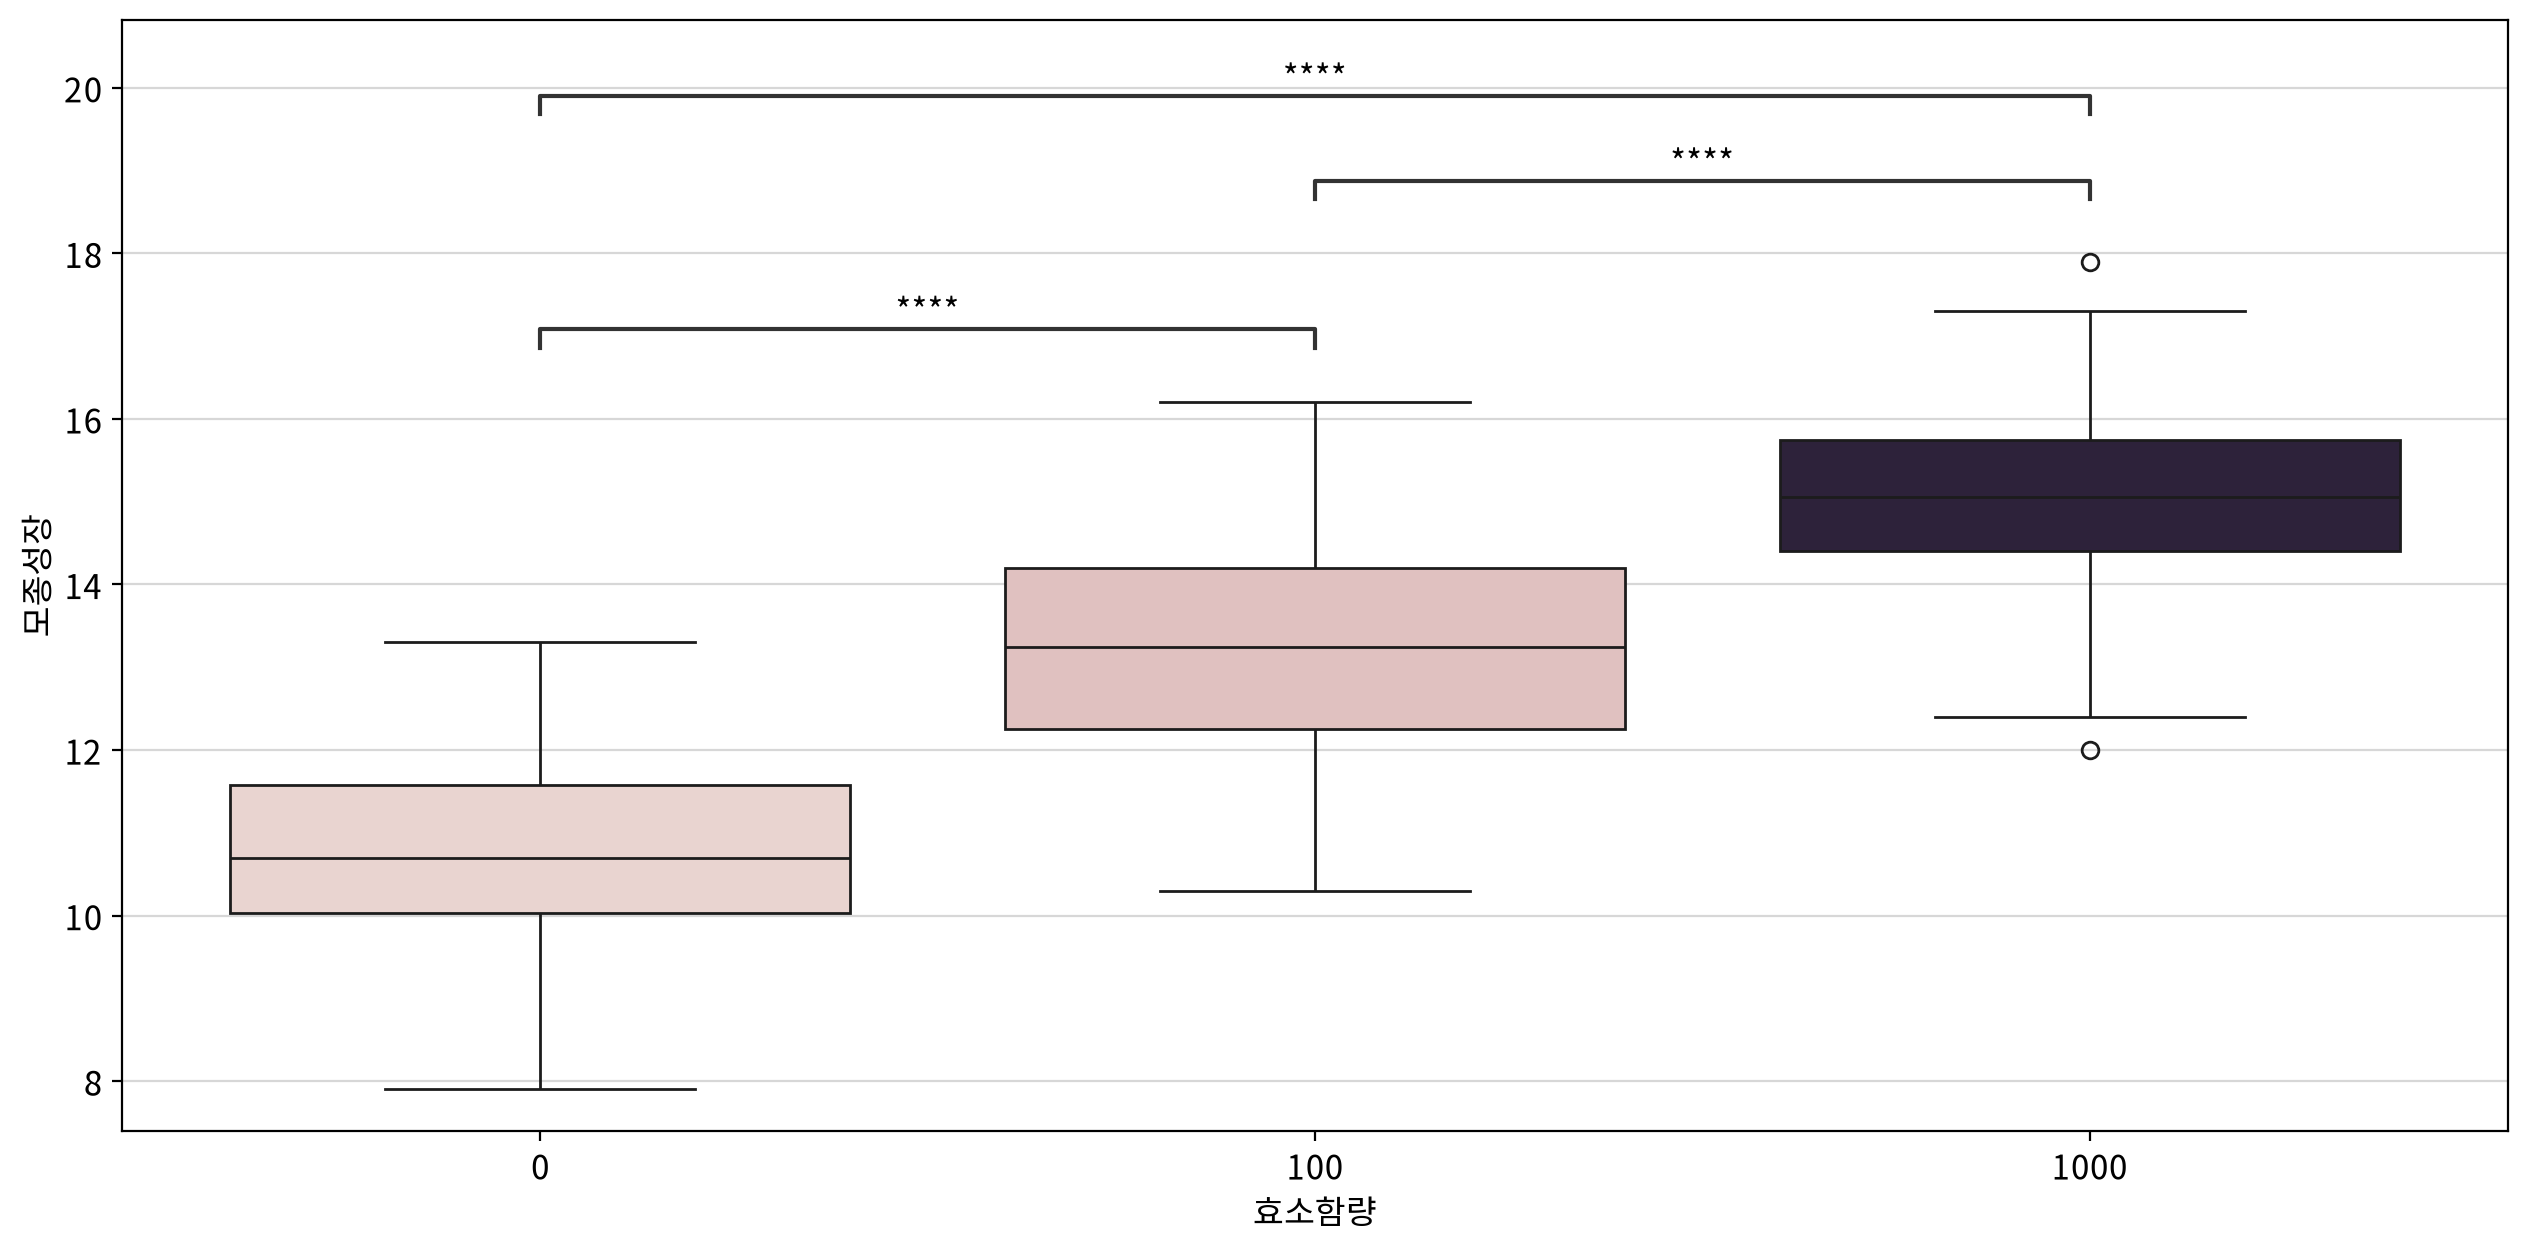

비교한 조합 쌍: 3개
유의한 쌍: 3개
평균 차이가 가장 큰 쌍: (0) vs (1000) → 차이 4.303, 효과크기 Large, p-value 0.000
평균 차이가 가장 작은 쌍: (100) vs (1000) → 차이 1.877, 효과크기 Large, p-value 0.000


,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,0,100,10.753,13.180,-2.427,0.339,-7.162,0.000,-1.868,True,Large
1,Tukey HSD,0,1000,10.753,15.057,-4.303,0.339,-12.701,0.000,-3.316,True,Large
2,Tukey HSD,100,1000,13.180,15.057,-1.877,0.339,-5.539,0.000,-1.351,True,Large


In [32]:
my_stats.posthoc_oneway(df4, y='모종성장', between='효소함량')

> 사후 분석 결과, 모든 집단의 평균 차이가 통계적으로 유의하였다 (*p* < 0.05).
> 
> 0과 100 두 집단의 평균은 각각 10.753과 13.180으로 평균 차이는 -2.427이었으며, 효과크기(Hedges' g)는 -1.868로 큰 수준이었다.   
> 즉, **0 집단의 평균이 100 집단보다 유의하게 낮았다.**   
> 0과 1000 두 집단의 평균은 각각 10.753과 15.057으로 평균 차이는 -4.303이었으며, 효과크기(Hedges' g)는 -3.316로 큰 수준이었다.   
> 즉, **0 집단의 평균이 1000 집단보다 유의하게 낮았다.**   
> 100과 1000 두 집단의 평균은 각각 13.180과 15.057으로 평균 차이는 -1.877이었으며, 효과크기(Hedges' g)는 -1.351로 큰 수준이었다.   
> 즉, **100 집단의 평균이 1000 집단보다 유의하게 낮았다.**
> - **결론**: 토마토 모종 포기의 성장은 모든 효소 함량 조합에서 서로 통계적으로 유의하게 다르며, 특히 효소함량이 1000일 때의 모종성장이 가장 컸고, 0일때의 성장이 가장 작았다.